The way to determine if the parameters for PSF resampler are correct is to check how the PSD before and after resampling compare.

This notebook explores the computation of spectra for both input and resampled.

I am selecting a square area in healpix (rotated by 45°).
A parent cell barely fits the swath, not ideal.
I start from a center pixel, that I enlarge using healpix_geo.nested.kth_neighbourhood.
If I put those cell ids in ring, they can be sorted (left to right, top ring to bottom ring) and then reordered to be wrapped in a 2D array.

In [1]:
import logging
from dataclasses import dataclass
from os import path

import cartopy.crs as ccrs
import healpix_geo.ring
import healpix_geo.nested
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
import xarray as xr
from cdshealpix import to_ring
from healpix_resample import PSFResampler
from healpix_resample.base import ResampleResults
from matplotlib.collections import PolyCollection

from swot_healpix.analysis.spectra import FFTComputer, average_psd_azimuth
from swot_healpix.data import SWOT
from swot_healpix.utils import format_latlon, get_cell_size

%matplotlib inline

log = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO)

In [2]:
level = 15
cell_size = get_cell_size(level)

plot_dir = "/home/chaeck/Data/Plots/spectra_check"

# Definitions

In [3]:
def reindex_ring_to_2d(n_side: int) -> np.ndarray:
    """Return indices to reorder cells from ring order to 2d.

    This uses the fact that cells in the ring indexing scheme are arranged from left
    to right and top to bottom.

    To use those indices: Be sure to use 'ring' indexing scheme and that cells are
    sorted by id:
    ```
    cell_ids = to_ring(cell_ids, depth=level)
    sort_indices = np.argsort(cell_ids)
    cell_ids = cell_ids[sort_indices]
    cell_data = cell_data[sort_indices]
    ```
    Then to wrap data into a 2d array:
    ```
    cell_data_2d = np.zeros((2**level, 2**level))
    np.put(cell_data_2d, reindex_ring_to_2d(level), cell_data)
    ```

    Example (level 2)
    -----------------
    Left is ring-order, right is 2D (flattened) order.
    ```
              0                        15
           1     2                  14    11
        3     4     5            13    10     7
     6     7     8     9  =>  12     9     6     3
       10    11    12             8     5     2
          13    14                   4     1
             15                         0
    ```
    """
    indices = np.zeros(n_side**2, dtype="i8")
    i_cell_start = 0
    n_cell_ring = 1
    for _ in range(n_side):
        ix = np.arange(0, n_cell_ring)
        iy = np.arange(n_cell_ring - 1, -1, -1)
        indices[i_cell_start : i_cell_start + n_cell_ring] = iy * n_side + ix

        i_cell_start += n_cell_ring
        n_cell_ring += 1

    n_cell_ring -= 2

    for i_ring in range(n_side - 1):
        ix = np.arange(0, n_cell_ring) + i_ring + 1
        iy = np.arange(n_cell_ring - 1, -1, -1) + i_ring + 1
        indices[i_cell_start : i_cell_start + n_cell_ring] = iy * n_side + ix

        i_cell_start += n_cell_ring
        n_cell_ring -= 1

    indices = np.asarray(indices)
    return indices

In [4]:
# Load data
def load(cycle: int, track: int, lat: float, side: str = "left"):
    """Load SWOT data."""
    swot = SWOT(cycle=cycle, track=track, version="PGC0")
    swot_file = swot.get_file()
    swath = xr.open_dataset(swot_file, group=side, chunks=-1)

    center_lat = swath.latitude.isel(num_pixels=swath.num_pixels.size // 2).values
    center_lat = np.sort(center_lat)  # just in case, just only modify slighty over land
    i_line = np.searchsorted(center_lat, lat)

    swath = swath.isel(num_lines=slice(i_line - 250, i_line + 250))

    if side == "left":
        swath = swath.isel(num_pixels=slice(None, None, -1))
    if swot.pass_type == "descending":
        swath = swath.isel(num_lines=slice(None, None, -1))

    swath.longitude.load()
    swath.latitude.load()
    swath.ssh_karin_2.load()

    swath = swath.dropna("num_lines", how="all", subset=["longitude"])
    swath = swath.dropna("num_pixels", how="all", subset=["longitude"])

    swath["ssh_karin_2"] -= swath.ssh_karin_2.mean()

    return swath


def get_diamond(
    swath: xr.Dataset, n_ring: int, center_i_line: int | None = None
) -> tuple[int, np.ndarray]:
    """Find cell ids for a diamond centered on the swath."""
    if center_i_line is None:
        center_i_line = swath.num_lines.size // 2
    center_i_pixel = swath.num_pixels.size // 2
    center_pixel = swath.isel(num_pixels=center_i_pixel, num_lines=center_i_line)
    center_id = healpix_geo.nested.lonlat_to_healpix(
        float(center_pixel.longitude),
        float(center_pixel.latitude),
        depth=level,
        ellipsoid="WGS84",
    )
    n_side = 2 * n_ring + 1
    return n_side, healpix_geo.nested.kth_neighbourhood(
        center_id, depth=level, ring=n_ring
    )[0]


def resample(
    swath: xr.Dataset,
    diamond_cell_ids: np.ndarray,
    lam: float = 0.0,
    verbose: float = True,
    **kwargs,
) -> ResampleResults:
    """Resample SSH."""
    lon = swath.longitude.values.ravel()
    lat = swath.latitude.values.ravel()
    ssh = swath.ssh_karin_2.values.ravel()

    resampler = PSFResampler(
        lon_deg=lon, lat_deg=lat, level=level, out_cell_ids=diamond_cell_ids, **kwargs
    )
    resampled = resampler.resample(ssh, lam=lam)
    if verbose:
        print(
            f"{resampled.cg_niters} iterations, "
            f"final residual: {resampled.cg_residual_norms[-1]}"
        )
    return resampled


def reshape_resampled_2d(
    resampled: ResampleResults,
    n_side: int,
    indices: np.ndarray | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Wrap resampled data in 2D."""
    if indices is None:
        indices = reindex_ring_to_2d(n_side)

    cell_ids = to_ring(resampled.cell_ids, depth=level)
    i_sort = np.argsort(cell_ids)
    cell_ids = np.take(cell_ids, i_sort)
    ssh_hp = np.take(resampled.cell_data, i_sort)

    ssh_hp_2d = np.zeros((n_side, n_side))
    np.put(ssh_hp_2d, indices, ssh_hp)
    np.put(cell_ids, indices, cell_ids)
    return cell_ids, ssh_hp_2d


def get_resolution(
    swath: xr.Dataset, verbose: bool = True, cross_track_margin: int = 30
) -> tuple[float, float]:
    """Get average resolution over swath."""
    # [(lon, lat), along-track, cross-track]
    r = np.stack([swath.longitude, swath.latitude], axis=0)

    factor = 6371e3 / 180 * np.pi
    dr_x = np.diff(r, axis=2) * factor
    dr_y = np.diff(r, axis=1) * factor

    # correct radius for longitude
    dr_x[0] *= np.cos(np.deg2rad(r[1, :, 1:]))
    dr_y[0] *= np.cos(np.deg2rad(r[1, 1:, :]))

    dx = np.mean(np.linalg.norm(dr_x[:, :-cross_track_margin], axis=0))
    dy = np.mean(np.linalg.norm(dr_y[:, :-cross_track_margin], axis=0))

    if verbose:
        print(f"Resolution cross-track: {dx:.1f}, along-track: {dy:.1f}")

    return dx, dy


def select_span(
    swath: xr.Dataset, n_side: int, dx: float = 250, dy: float = 250
) -> xr.Dataset:
    """Select span in the swath with the same size as the healpix diamond."""
    nx = int(n_side * cell_size / dx)
    ny = int(n_side * cell_size / dy)
    center_i_line = swath.num_lines.size // 2
    center_i_pixel = swath.num_pixels.size // 2
    iy0 = center_i_line - ny // 2
    iy1 = center_i_line + ny // 2
    ix0 = center_i_pixel - nx // 2
    ix1 = center_i_pixel + ny // 2

    if iy0 < 0 or iy1 > swath.num_lines.size or ix0 < 0 or ix1 > swath.num_pixels.size:
        print("Diamond is too big to fit in current swath :(")

    return swath.isel(
        num_lines=slice(max(0, center_i_line - ny // 2), center_i_line + ny // 2),
        num_pixels=slice(max(0, center_i_pixel - nx // 2), center_i_pixel + nx // 2),
    )


def compute_psd(
    ssh: np.ndarray, dx: float = 250, dy: float = 250
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute 2D PSD."""
    ny, nx = ssh.shape
    fft_c = FFTComputer(
        box_size_x=nx, box_size_y=ny, dx=dx, dy=dy, apodizing_kind="tukey"
    )

    psd_2d = fft_c.psd(ssh)
    fx, fy = fft_c.get_frequencies()
    fx *= 1000
    fy *= 1000

    return fx, fy, psd_2d

In [5]:
@dataclass
class StudyCase:
    name: str
    cycle: int
    track: int
    lat: float
    side: str = "left"

    def load(self) -> xr.Dataset:
        return load(cycle=self.cycle, track=self.track, lat=self.lat, side=self.side)


def get_cases() -> list[StudyCase]:
    return [
        StudyCase("long_swells", 546, 19, lat=-46.96),
        StudyCase("remote_reflections", 547, 21, lat=-45.4),
        StudyCase("crossing_swells", 548, 17, lat=-29.3),
    ]


cases = get_cases()

In [6]:
def all_in_one(
    swath: xr.Dataset,
    lam: float = 0.0,
    sigma_m: float | None = None,
    threshold: float = 0.1,
    verbose: bool = False,
) -> xr.Dataset:
    """Do all processing at once. Return 1D PSD."""
    n_ring = 100
    n_side, diamond_cell_ids = get_diamond(swath, n_ring)

    resampled = resample(
        swath,
        diamond_cell_ids,
        lam=lam,
        threshold=threshold,
        sigma_m=sigma_m,
    )

    cell_ids, ssh_hp_2d = reshape_resampled_2d(resampled, n_side)

    dx, dy = get_resolution(swath, verbose=verbose)

    span = select_span(swath, n_side, dx, dy)

    fx, fy, psd_2d = compute_psd(span.ssh_karin_2.values, dx, dy)
    fr, psd_1d = average_psd_azimuth(psd_2d, fx, fy)

    fx_hp, fy_hp, psd_2d_hp = compute_psd(ssh_hp_2d, cell_size, cell_size)
    fr_hp, psd_1d_hp = average_psd_azimuth(psd_2d_hp, fx_hp, fy_hp)

    ds = xr.Dataset(
        {
            "psd": (("fr"), psd_1d),
            "psd_hp": (("fr_hp"), psd_1d_hp),
        },
        coords={
            "fr": fr,
            "fr_hp": fr_hp,
        },
    )
    return ds

# Single image

First case study (long-swells).

## Load data

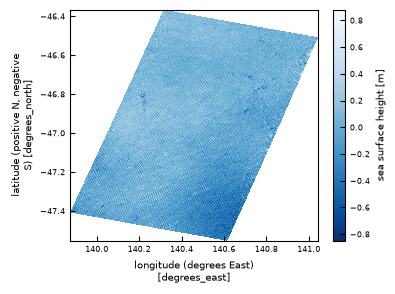

In [7]:
swath = cases[0].load()

fig, ax = plt.subplots(figsize=(4, 3))
swath.ssh_karin_2.plot.pcolormesh(
    x="longitude", y="latitude", center=False, cmap="Blues_r"
)

## Select diamond

Find a large healpix diamond centered on the swath in and find reshape it in 2D

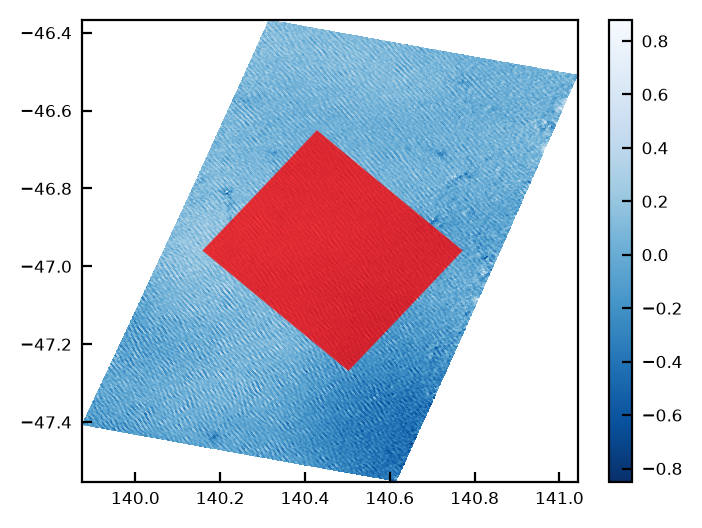

In [8]:
n_ring = 100
n_side, diamond_cell_ids = get_diamond(swath, n_ring)

fig, ax = plt.subplots(figsize=(4, 3), dpi=200)
swath.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    center=False,
    cmap="Blues_r",
    add_labels=False,
)
vertices = np.stack(
    healpix_geo.nested.vertices(diamond_cell_ids, depth=level, ellipsoid="WGS84"),
    axis=-1,
)
ax.add_artist(PolyCollection(vertices, ec="r", lw=0.2, fc="none", alpha=0.5))

## Find SWOT pixel size

We need it to select a region of the same size as our healpix diamond.
We also need it to compute frequencies accurately.


In [9]:
cross_track_margin = 30
# Avoid that many pixels on the far edge cross-track when averaging pixel size

# [(lon, lat), along-track, cross-track]
r = np.stack([swath.longitude, swath.latitude], axis=0)

factor = 6371e3 / 180 * np.pi
dr_x = np.diff(r, axis=2) * factor
dr_y = np.diff(r, axis=1) * factor

# correct radius for longitude
dr_x[0] *= np.cos(np.deg2rad(r[1, :, 1:]))
dr_y[0] *= np.cos(np.deg2rad(r[1, 1:, :]))

dr_x = np.linalg.norm(dr_x, axis=0)
dr_y = np.linalg.norm(dr_y, axis=0)

Text(0, 0.5, 'Along-track')

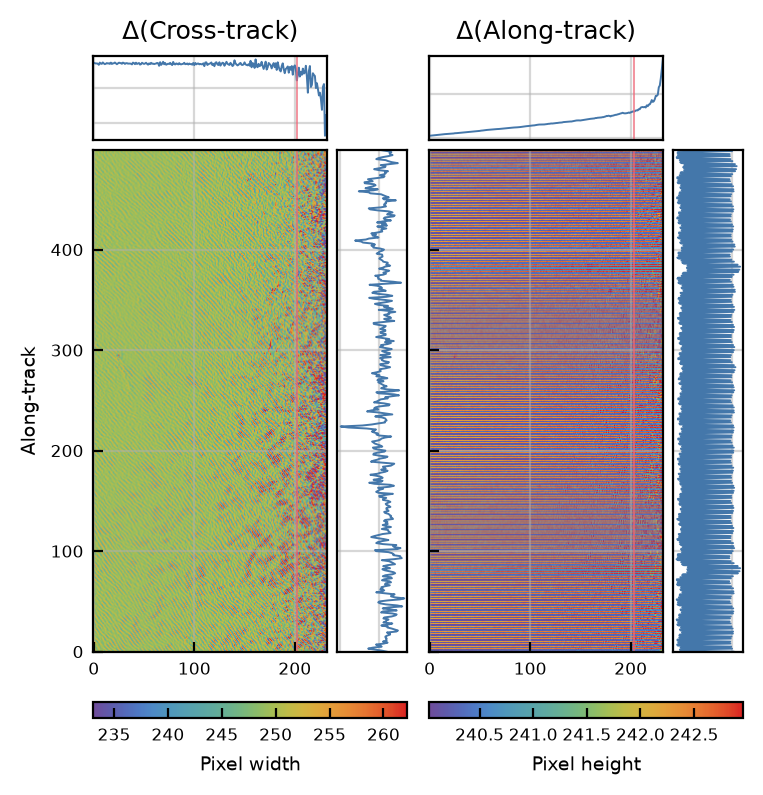

In [67]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, axes = plt.subplots(
    1, 2, sharex=True, sharey=True, layout="constrained", figsize=(3.7, 3.7), dpi=200
)
labels = (["Δ(Cross-track)", "width"], ["Δ(Along-track)", "height"])

for ax, dr, (title, unit) in zip(axes, [dr_x, dr_y], labels):
    vmin = np.quantile(dr, 0.01)
    vmax = np.quantile(dr, 0.99)
    im = ax.imshow(dr, origin="lower", vmin=vmin, vmax=vmax, cmap=tc.rainbow_PuRd)

    divider = make_axes_locatable(ax)
    ax_avg_x = divider.append_axes("top", 0.42, pad=0.05, sharex=ax)
    ax_avg_y = divider.append_axes("right", 0.35, pad=0.05, sharey=ax)
    ax_avg_x.tick_params(labelbottom=False, labelleft=False, left=False, bottom=False)
    ax_avg_y.tick_params(labelbottom=False, labelleft=False, left=False, bottom=False)

    ax_avg_x.plot(np.mean(dr, axis=0), lw=0.7)
    ax_avg_y.plot(np.mean(dr, axis=1), np.arange(dr.shape[0]), lw=0.7)

    ax_avg_x.set_title(title)

    for ax_ in (ax, ax_avg_x):
        ax_.axvline(dr.shape[1] - cross_track_margin, lw=0.7, alpha=0.7, color=tc.bright.red)

    fig.colorbar(im, ax=ax, location="bottom", label=f"Pixel {unit}")
axes[0].set_ylabel("Along-track")

Text(0.5, 0, 'Cross-track pixel index')

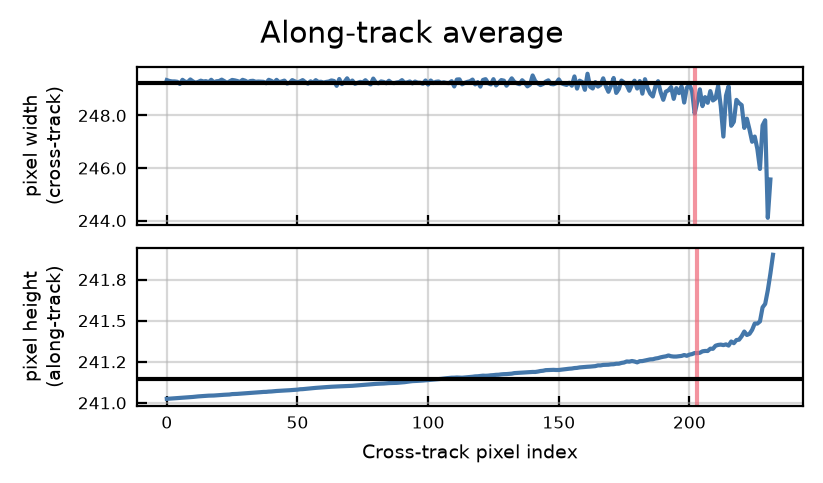

In [11]:
fig, axes = plt.subplots(
    2, 1, sharex=True, figsize=(4, 2.3), dpi=200, layout="constrained"
)
fig.suptitle("Along-track average")

for ax, dr, label in zip(
    axes, [dr_x, dr_y], ("width\n(cross-track)", "height\n(along-track)")
):
    ax.set_ylabel("pixel " + label)
    ax.plot(np.mean(dr, axis=0))
    ax.axvline(
        dr.shape[1] - cross_track_margin, color=tc.bright.red, alpha=0.7
    )
    ax.axhline(np.mean(dr[:, :-cross_track_margin]), color="k")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{x:.1f}"))

axes[1].set_xlabel("Cross-track pixel index")

In [12]:
dx, dy = get_resolution(swath, cross_track_margin=cross_track_margin)
dx, dy

Resolution cross-track: 249.1, along-track: 241.2


(np.float64(249.05179584217433), np.float64(241.1834063493452))

## Select span

with the same size (in meters) as the healpix diamond.

In [13]:
span = select_span(swath, n_side, dx, dy)

## Resample

and reshape to 2D

In [14]:
resampled = resample(swath, diamond_cell_ids, lam=0.5)

cell_ids, ssh_hp_2d = reshape_resampled_2d(resampled, n_side)

/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:346: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/Context.cpp:816.)
  M_coo = torch.sparse_coo_tensor(
/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:570: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/S

13 iterations, final residual: [5.1823548e-08]


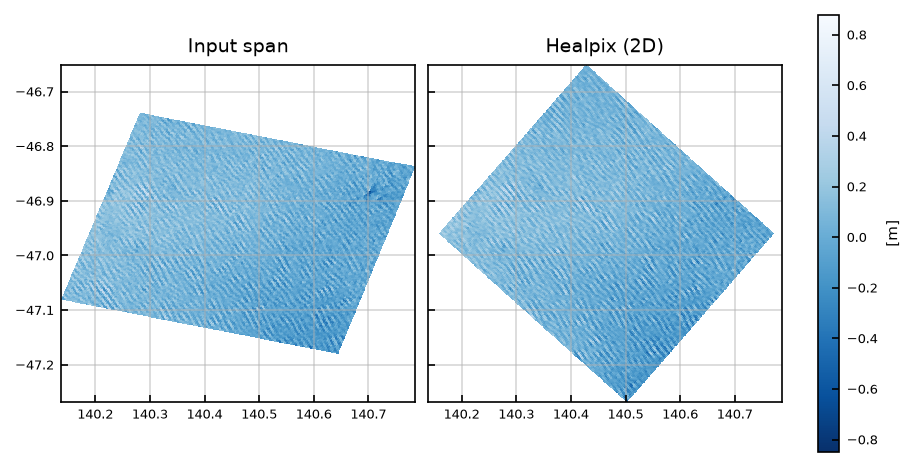

In [15]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(6, 3),
    layout="constrained",
    sharex=True,
    sharey=True,
    dpi=150,
)
ax1, ax2 = axes

vmin = float(swath.ssh_karin_2.min())
vmax = float(swath.ssh_karin_2.max())

im = span.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    vmin=vmin,
    vmax=vmax,
    ax=ax1,
    add_labels=False,
    add_colorbar=False,
    cmap="Blues_r",
)
ax1.set_title("Input span")

diamond_lon, diamond_lat = healpix_geo.ring.healpix_to_lonlat(
    cell_ids, depth=level, ellipsoid="WGS84"
)
diamond_lon_2d = np.reshape(diamond_lon, (n_side, n_side))
diamond_lat_2d = np.reshape(diamond_lat, (n_side, n_side))

ax2.pcolormesh(diamond_lon_2d, diamond_lat_2d, ssh_hp_2d, vmin=vmin, vmax=vmax, cmap="Blues_r")
ax2.set_title("Healpix (2D)")

# ax1.set_xlim(np.min(diamond_lon), np.max(diamond_lon))
# ax1.set_ylim(np.min(diamond_lat), np.max(diamond_lat))

fig.colorbar(im, ax=axes, label="[m]")

for ax in axes:
    ax.set_aspect("equal")
    ax.grid(True)

## Spectra

In [64]:
# Input
fx, fy, psd_2d = compute_psd(span.ssh_karin_2.values, dx, dy)
fr, psd_1d = average_psd_azimuth(psd_2d, fx, fy)

# Resampled
fx_hp, fy_hp, psd_2d_hp = compute_psd(ssh_hp_2d, cell_size, cell_size)
fr_hp, psd_1d_hp = average_psd_azimuth(psd_2d_hp, fx_hp, fy_hp)

Text(0, 0.5, '[cycle/km]')

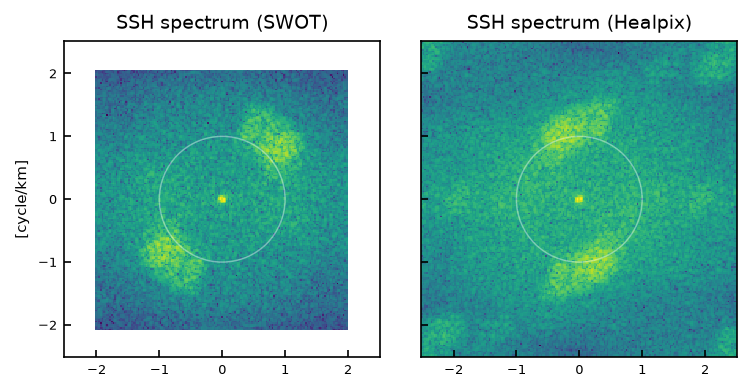

In [65]:
fig, axes = plt.subplots(
    1, 2, layout="constrained", figsize=(5, 2.5), dpi=150, sharex=True, sharey=True
)
ax1, ax2 = axes

ax1.pcolormesh(fx, fy, psd_2d, norm="log")
ax1.set_title("SSH spectrum (SWOT)")
ax2.pcolormesh(fx_hp, fy_hp, psd_2d_hp, norm="log")
ax2.set_title("SSH spectrum (Healpix)")

#ax1.set_xlim(fx[0], fx[-1])
#ax1.set_ylim(fy[0], fy[-1])

for ax in axes:
    ax.set_aspect("equal")
    ax.grid(False)

    for dist in [1000]:
        ax.add_artist(plt.Circle(
            (0, 0),
            radius=1/(dist/1000),
            lw=0.7,
            ec="w",
            alpha=0.4,
            fc="none",
        ))

ax1.set_ylabel("[cycle/km]")

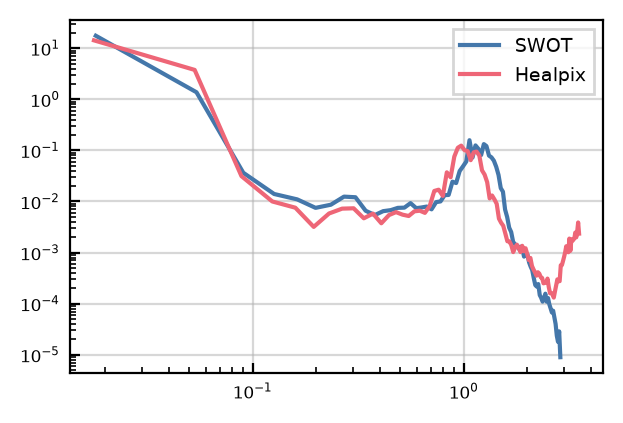

In [66]:
fig, ax = plt.subplots(layout="constrained", figsize=(3, 2), dpi=200)
ax.plot(fr, psd_1d, label="SWOT")
ax.plot(fr_hp, psd_1d_hp, label="Healpix")
ax.legend()
ax.set_xscale("log")
ax.set_yscale("log")

## Shift of peak

Peak SWOT: 1.141 km-1
Peak resampled: 1.025 km-1
Shift de 99.58 m


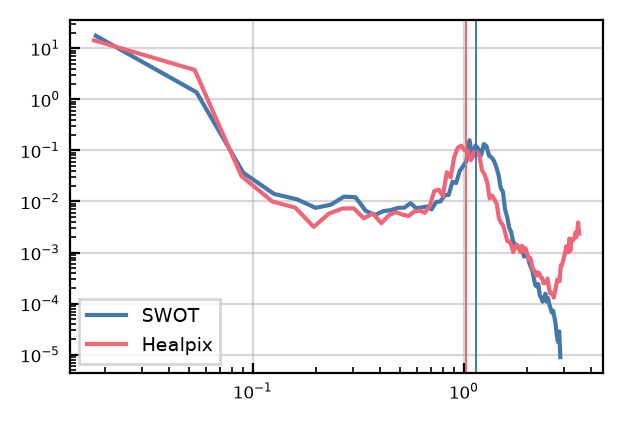

In [57]:
from scipy.optimize import curve_fit


def get_gaussian_peak(x: np.ndarray, y: np.ndarray, guess: float, bounds: tuple[float, float]) -> float:
    i_bounds = np.searchsorted(x, bounds)

    x = x[slice(*i_bounds)]
    y = y[slice(*i_bounds)]
    x = np.log(x)
    y = np.log(y)

    def gauss(x, B, A, x0, std):
        return B + A * np.exp(-0.5 * (x - x0) ** 2 / std**2)

    ymin = np.min(y)
    ymax = np.max(y)
    B = min(ymax / 4, np.min(y))
    p0 = [ymin, ymax-ymin, np.log(guess), 0.1]

    bounds = [
        (-np.inf, 1e-3, np.log(bounds[0]), 1e-3),
        (np.inf, 20, np.log(bounds[1]), 10),
    ]
    p, _ = curve_fit(gauss, x, y, p0, bounds=bounds)
    return np.exp(p[2])


guess = 1.5
bounds = [0.8, 2]
peak = get_gaussian_peak(fr, psd_1d, guess=guess, bounds=bounds)
peak_hp = get_gaussian_peak(fr_hp, psd_1d_hp, guess=guess, bounds=bounds)

print(f"Peak SWOT: {peak:.3f} km-1")
print(f"Peak resampled: {peak_hp:.3f} km-1")
print(f"Shift de {abs(1./peak-1./peak_hp)*1000:.2f} m")

fig, ax = plt.subplots(layout="constrained", figsize=(3, 2), dpi=200)
ax.plot(fr, psd_1d, color=tc.bright.blue, label="SWOT")
ax.plot(fr_hp, psd_1d_hp, color=tc.bright.red, label="Healpix")

ax.axvline(peak, color=tc.bright.blue, lw=0.7)
ax.axvline(peak_hp, color=tc.bright.red, lw=0.7)

ax.legend()
ax.set_xscale("log")
ax.set_yscale("log")

# Multiple chunks along swath

Compute spectra for multiple chunk along the swath, average spectras.
The swath must not pass through wrapping longitude (180°E), otherwise the code reshaping the chunk in 2d will fail silently.

In [51]:
track = SWOT(cycle=546, track=19, version="PGC0")
swot_file = track.get_file()
swath = xr.open_dataset(swot_file, group="left", chunks=-1)

swath = swath.isel(num_lines=slice(42_000, 62_000))

# Left swath, we flip to have ascending longitude
swath = swath.isel(num_pixels=slice(None, None, -1))
if track.pass_type == "descending":
    swath = swath.isel(num_lines=slice(None, None, -1))

swath.longitude.load()
swath.latitude.load()
swath.ssh_karin_2.load()
swath.ancillary_surface_classification_flag.load()

swath = swath.dropna("num_lines", how="all", subset=["longitude"])
swath = swath.dropna("num_pixels", how="any", subset=["longitude"])

# swath = swath.isel(num_lines=slice(0, swath.num_pixels.size))

swath["ssh_karin_2"] -= swath.ssh_karin_2.mean()

swath

<xarray.Dataset> Size: 466MB
Dimensions:                                (num_lines: 20000, num_pixels: 233)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 37MB ...
    longitude                              (num_lines, num_pixels) float64 37MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/16)
    time                                   (num_lines) datetime64[ns] 160kB dask.array<chunksize=(20000,), meta=np.ndarray>
    time_tai                               (num_lines) datetime64[ns] 160kB dask.array<chunksize=(20000,), meta=np.ndarray>
    latitude_uncert                        (num_lines, num_pixels) float64 37MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    longitude_uncert                       (num_lines, num_pixels) float64 37MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    polarization_karin                     (num_lines) object 160kB dask.array<chunksize=(20000,), meta=np.ndarray>
    ssh_karin_2                            (num_lines, num_pixels) float64 37MB ...
    ...                                     ...
    sig0_karin_uncert                      (num_lines, num_pixels) float32 19MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    total_coherence                        (num_lines, num_pixels) float64 37MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    mean_sea_surface_cnescls               (num_lines, num_pixels) float64 37MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    miti_power_250m                        (num_lines, num_pixels) float32 19MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    miti_power_var_250m                    (num_lines, num_pixels) float32 19MB dask.array<chunksize=(20000, 233), meta=np.ndarray>
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 19MB ...
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

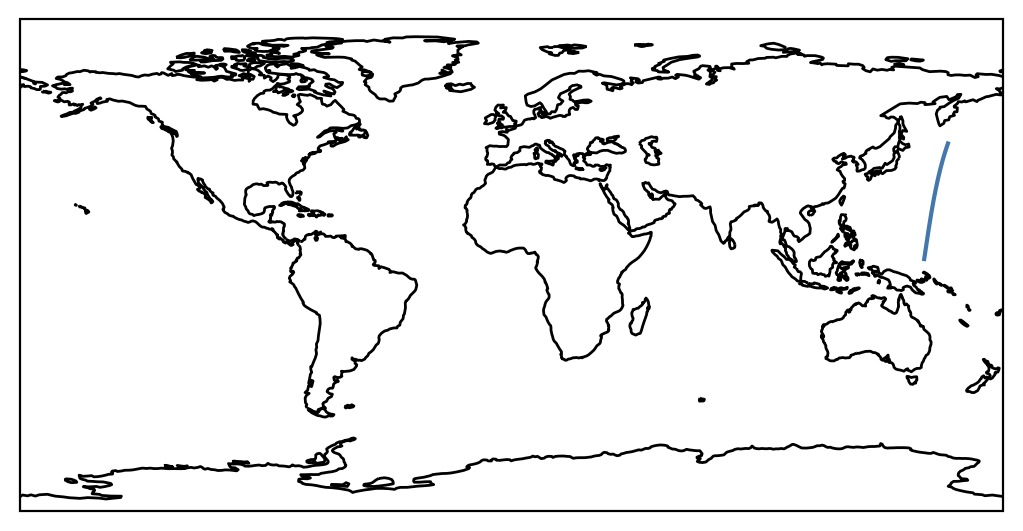

In [52]:
center_line = swath.isel(num_pixels=swath.num_pixels.size // 2)
fig, ax = plt.subplots(
    layout="constrained",
    figsize=(5, 3),
    dpi=200,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
ax.plot(center_line.longitude, center_line.latitude)
#swath.ssh_karin_2.plot.pcolormesh(x="longitude", y="latitude")
ax.set_global()
ax.coastlines()

In [77]:
def plot_check_reshape(i_chunk, span, ssh_hp, ssh_hp_2d, chunk_lon_2d, chunk_lat_2d):
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(8.5, 3),
        layout="constrained",
        sharex=True,
        sharey=True,
        dpi=150,
    )
    ax1, ax2, ax3 = axes

    vmin = float(span.ssh_karin_2.min())
    vmax = float(span.ssh_karin_2.max())

    im = span.ssh_karin_2.plot.pcolormesh(
        x="longitude",
        y="latitude",
        vmin=vmin,
        vmax=vmax,
        ax=ax1,
        add_labels=False,
        add_colorbar=False,
    )
    ax1.set_title("SWOT")

    vertices = np.stack(
        healpix_geo.nested.vertices(ssh_hp.cell_ids, depth=level, ellipsoid="WGS84"),
        axis=-1,
    )
    colorizer = plt.Colorizer(norm=plt.Normalize(vmin=vmin, vmax=vmax))
    colors = colorizer.to_rgba(ssh_hp.cell_data)
    polys = PolyCollection(vertices, ec=colors, fc=colors)
    ax2.add_collection(polys)
    ax2.set_title("Healpix")

    # ax1.add_collection(PolyCollection(vertices, ec="w", fc="none", lw=0.5, alpha=0.2))

    ax3.pcolormesh(chunk_lon_2d, chunk_lat_2d, ssh_hp_2d, vmin=vmin, vmax=vmax)
    ax3.set_title("Healpix (2D)")

    ax1.set_xlim(np.min(diamond_lon), np.max(diamond_lon))
    ax1.set_ylim(np.min(diamond_lat), np.max(diamond_lat))

    fig.colorbar(im, ax=axes, label="[m]")

    for ax in axes:
        ax.set_aspect("equal")
        ax.grid(True)

    fig.savefig(path.join(plot_dir, f"chunk_{i_chunk}_check_reshape.png"))
    plt.close(fig)

In [39]:
def plot_psd_2d(fx, fy, psd_2d, fx_hp, fy_hp, psd_2d_hp):
    fig, axes = plt.subplots(
        1, 2, layout="constrained", figsize=(5, 2.5), dpi=150, sharex=True, sharey=True
    )
    ax1, ax2 = axes

    ax1.pcolormesh(fx, fy, psd_2d, norm="log")
    ax1.set_title("SSH spectrum (SWOT)")
    ax2.pcolormesh(fx_hp, fy_hp, psd_2d_hp, norm="log")
    ax2.set_title("SSH spectrum (Healpix)")

    ax1.set_xlim(fx[0], fx[-1])
    ax1.set_ylim(fy[0], fy[-1])

    for ax in axes:
        ax.set_aspect("equal")
        ax.grid(False)

        for dist in [1000]:
            ax.add_artist(
                plt.Circle(
                    (0, 0),
                    radius=1 / (dist / 1000),
                    lw=0.7,
                    ec="w",
                    alpha=0.4,
                    fc="none",
                )
            )

    ax1.set_ylabel("[cycle/km]")

    fig.savefig(path.join(plot_dir, f"chunk_{i_chunk}_fft_2d.png"))
    plt.close(fig)

In [44]:
def plot_psd_1d(fr, psd_1d, fr_hp, psd_1d_hp):
    fig, ax = plt.subplots(layout="constrained", figsize=(3, 2), dpi=200)
    ax.plot(fr, psd_1d, label="SWOT")
    ax.plot(fr_hp, psd_1d_hp, label="Healpix")
    ax.legend()
    ax.set_xscale("log")
    ax.set_yscale("log")

    fig.savefig(path.join(plot_dir, f"chunk_{i_chunk}_fft_1d.png"))
    plt.close(fig)

In [ ]:
n_ring = 90
n_side = 2 * n_ring + 1
ring2d_indices = reindex_ring_to_2d(n_side)

threshold = 0.1
lam = 0.05
sigma_m = cell_size / 2

chunk_step = 2000
chunk_indices = np.arange(0, swath.num_lines.size + chunk_step, chunk_step)
chunk_indices = ((chunk_indices[1:] + chunk_indices[:-1]) / 2).astype("i")

do_plots = False

psd_list = []
psd_hp_list = []

for i_chunk, chunk_i0 in enumerate(chunk_indices):
    print(f"Chunk #{i_chunk + 1}/{len(chunk_indices)}")
    _, diamond_cell_ids = get_diamond(swath, n_ring, center_i_line=chunk_i0)

    if diamond_cell_ids.size != n_side**2:
        print("Chunk has incorrect size, skipping")
        continue

    swath_chunk = swath.isel(num_lines=slice(chunk_i0 - 150, chunk_i0 + 150))

    resampled = resample(
        swath_chunk, diamond_cell_ids, lam=lam, threshold=threshold, sigma_m=sigma_m
    )

    if np.any(~np.isfinite(resampled.cell_data)):
        print("Found Nan in resampled data, skipping")
        continue

    cell_ids, ssh_hp_2d = reshape_resampled_2d(resampled, n_side, ring2d_indices)

    diamond_lon, diamond_lat = healpix_geo.ring.healpix_to_lonlat(
        cell_ids, depth=level, ellipsoid="WGS84"
    )
    diamond_lon_2d = np.reshape(diamond_lon, (n_side, n_side))
    diamond_lat_2d = np.reshape(diamond_lat, (n_side, n_side))

    dx, dy = get_resolution(swath)
    span = select_span(swath, n_side, dx, dy)

    if do_plots:
        plot_check_reshape(
            i_chunk, span, resampled, ssh_hp_2d, diamond_lon_2d, diamond_lat_2d
        )

    fx, fy, psd_2d = compute_psd(span.ssh_karin_2.values, dx, dy)
    fr, psd_1d = average_psd_azimuth(psd_2d, fx, fy)

    fx_hp, fy_hp, psd_2d_hp = compute_psd(ssh_hp_2d, cell_size, cell_size)
    fr_hp, psd_1d_hp = average_psd_azimuth(psd_2d_hp, fx_hp, fy_hp)

    if do_plots:
        plot_psd_1d(fr, psd_1d, fr_hp, psd_1d_hp)
        plot_psd_2d(fx, fy, psd_2d, fx_hp, fy_hp, psd_2d_hp)

    psd_list.append(psd_1d)
    psd_hp_list.append(psd_1d_hp)

In [57]:
psd_1d_avg = np.mean(np.stack(psd_list), axis=0)
psd_1d_hp_avg = np.mean(np.stack(psd_hp_list), axis=0)

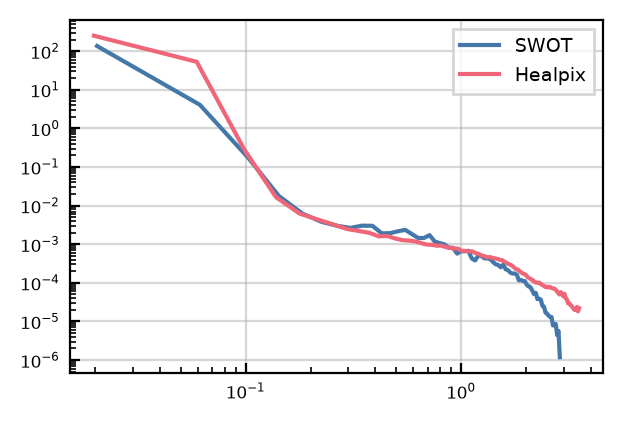

In [58]:
fig, ax = plt.subplots(layout="constrained", figsize=(3, 2), dpi=200)
ax.plot(fr, psd_1d_avg, label="SWOT")
ax.plot(fr_hp, psd_1d_hp_avg, label="Healpix")
ax.legend()
ax.set_xscale("log")
ax.set_yscale("log")
fig.savefig(
    path.join(plot_dir, f"spectra_comp_thr{threshold:.2f}_lam{lam:.2f}_sigdef.png")
)

# Study cases

Use 3 different study cases (selected from Ardhuin 2024).

In [237]:
# Load data
cases = get_cases()
for case in cases:
    case.swath = case.load()

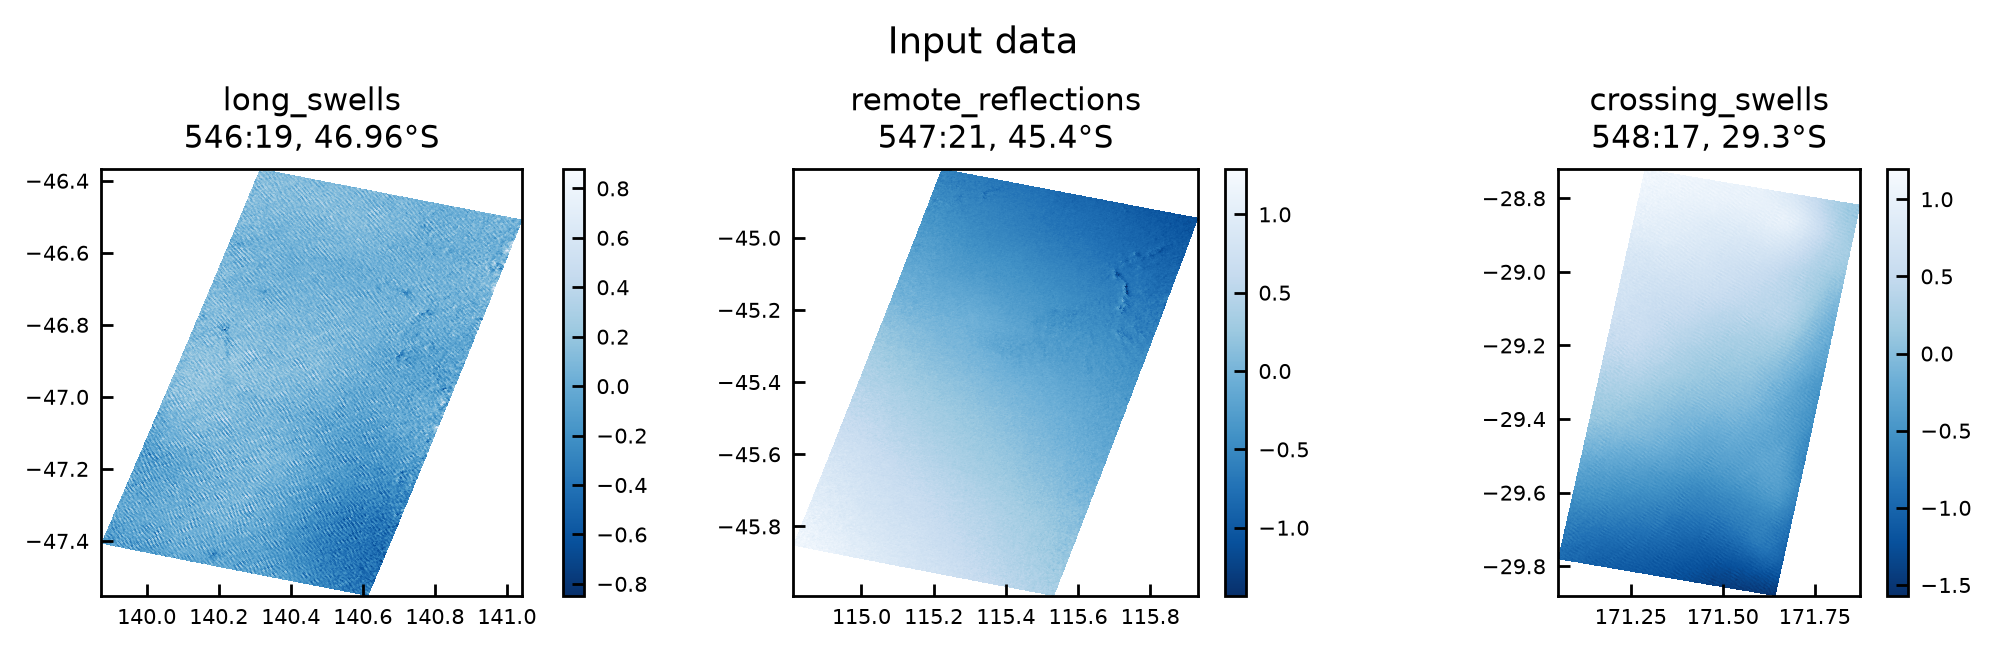

In [238]:
fig, axes = plt.subplots(1, 3, figsize=(8, 2.5), dpi=250, layout="constrained")
fig.suptitle("Input data")

for ax, c in zip(axes.flat, cases):
    c.swath.ssh_karin_2.plot.pcolormesh(
        x="longitude",
        y="latitude",
        add_labels=False,
        center=False,
        cmap="Blues_r",
        ax=ax,
    )
    ax.set_title(f"{c.name}\n{c.cycle}:{c.track}, {format_latlon(c.lat, 'lat')}")
    ax.set_aspect("equal")

In [239]:
# Resample, reshape, select span
n_ring = 100
n_side = 2 * n_ring + 1
indices = reindex_ring_to_2d(n_side)

for case in cases:
    case.n_side, case.diamond_cell_ids = get_diamond(case.swath, n_ring)

    case.resampled = resample(
        case.swath, case.diamond_cell_ids, lam=0.5, threshold=0.1, sigma_m=None
    )

    case.cell_ids, case.ssh_hp_2d = reshape_resampled_2d(
        case.resampled, n_side, indices
    )

    diamond_lon, diamond_lat = healpix_geo.ring.healpix_to_lonlat(
        case.cell_ids, depth=level, ellipsoid="WGS84"
    )
    case.diamond_lon_2d = np.reshape(diamond_lon, (n_side, n_side))
    case.diamond_lat_2d = np.reshape(diamond_lat, (n_side, n_side))

    case.dx, case.dy = get_resolution(case.swath)
    case.span = select_span(case.swath, n_side, case.dx, case.dy)

13 iterations, final residual: [5.1823548e-08]
Resolution cross-track: 249.1, along-track: 241.2
14 iterations, final residual: [5.22773e-09]
Resolution cross-track: 249.1, along-track: 241.1
13 iterations, final residual: [1.4786921e-08]
Resolution cross-track: 249.5, along-track: 240.4


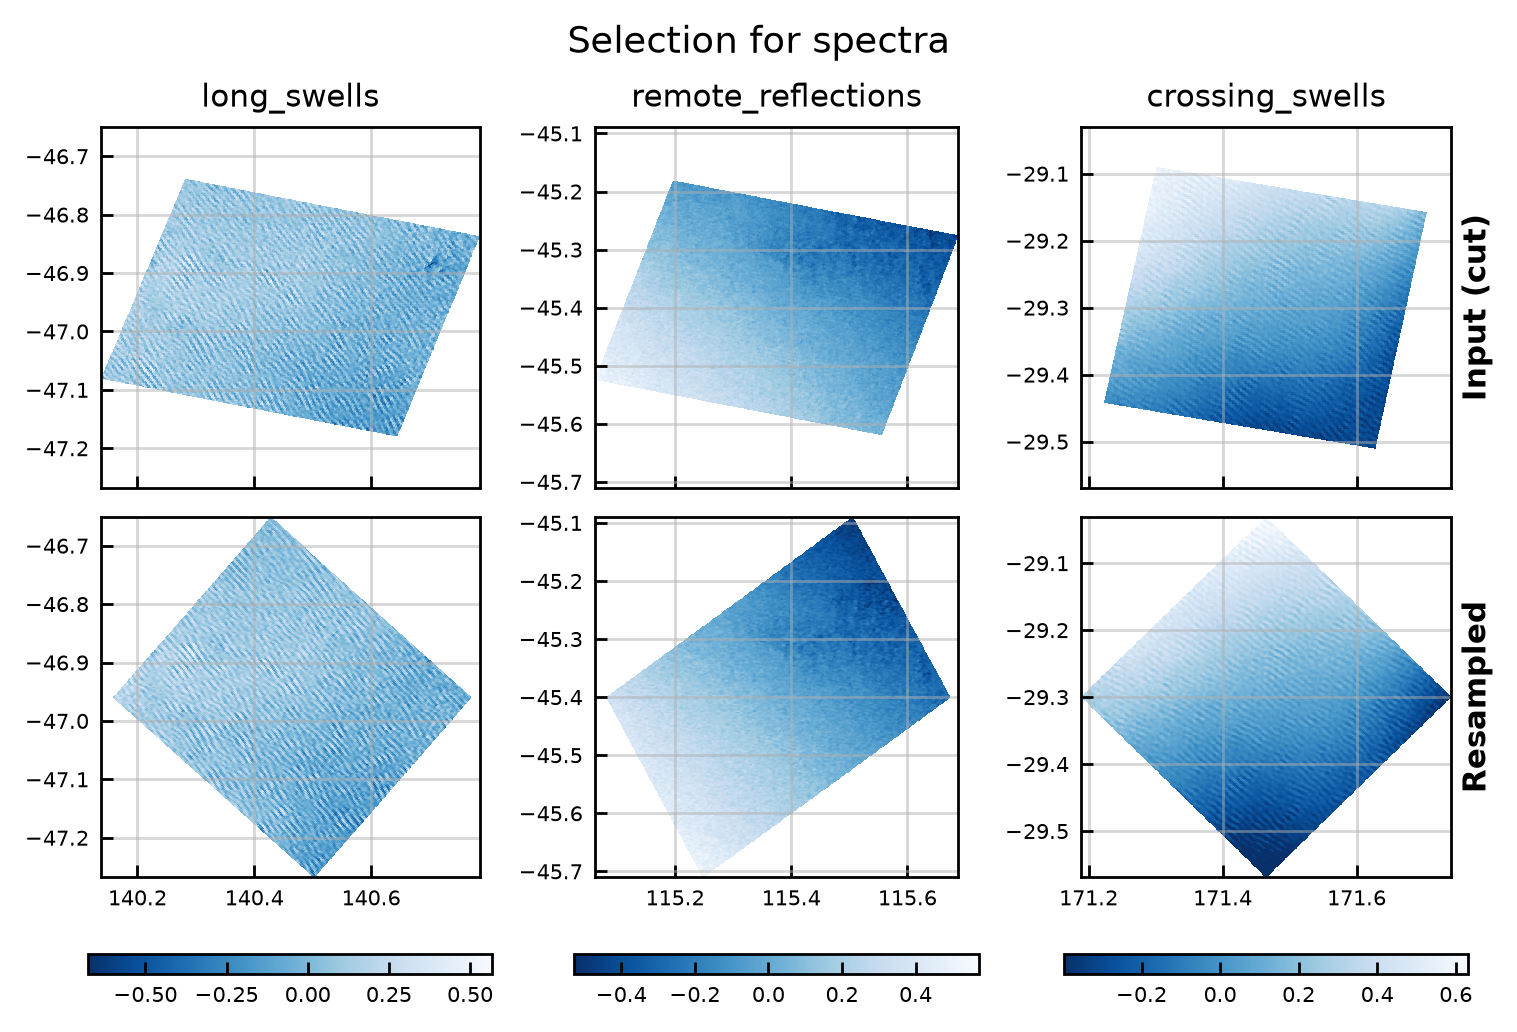

In [240]:
fig, axes = plt.subplots(
    2, 3, figsize=(6, 4), dpi=250, layout="constrained", sharex="col", sharey="col"
)
fig.suptitle("Selection for spectra")

for axes_col, c in zip(axes.T, cases):
    ax1, ax2 = axes_col
    vmin = float(c.span.ssh_karin_2.min())
    vmax = float(c.span.ssh_karin_2.max())
    kwargs = dict(cmap="Blues_r", vmin=vmin, vmax=vmax)

    im = ax1.pcolormesh(c.span.longitude, c.span.latitude, c.span.ssh_karin_2, **kwargs)
    ax2.pcolormesh(c.diamond_lon_2d, c.diamond_lat_2d, c.ssh_hp_2d, **kwargs)
    fig.colorbar(im, ax=axes_col, location="bottom")
    ax1.set_title(c.name)
    for ax in axes_col:
        ax.set_aspect("equal")

for ax, label in zip(axes[:, -1], ["Input (cut)", "Resampled"]):
    ax.annotate(
        label,
        xy=(1, 0.5),
        xycoords="axes fraction",
        xytext=(3, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        rotation=90,
        weight="bold",
    )

In [241]:
# Compute PSD
for case in cases:
    case.fx, case.fy, case.psd_2d = compute_psd(
        case.span.ssh_karin_2.values, case.dx, case.dy
    )
    case.fr, case.psd_1d = average_psd_azimuth(case.psd_2d, case.fx, case.fy)

    case.fx_hp, case.fy_hp, case.psd_2d_hp = compute_psd(case.ssh_hp_2d, 198, 198)
    case.fr_hp, case.psd_1d_hp = average_psd_azimuth(
        case.psd_2d_hp, case.fx_hp, case.fy_hp
    )

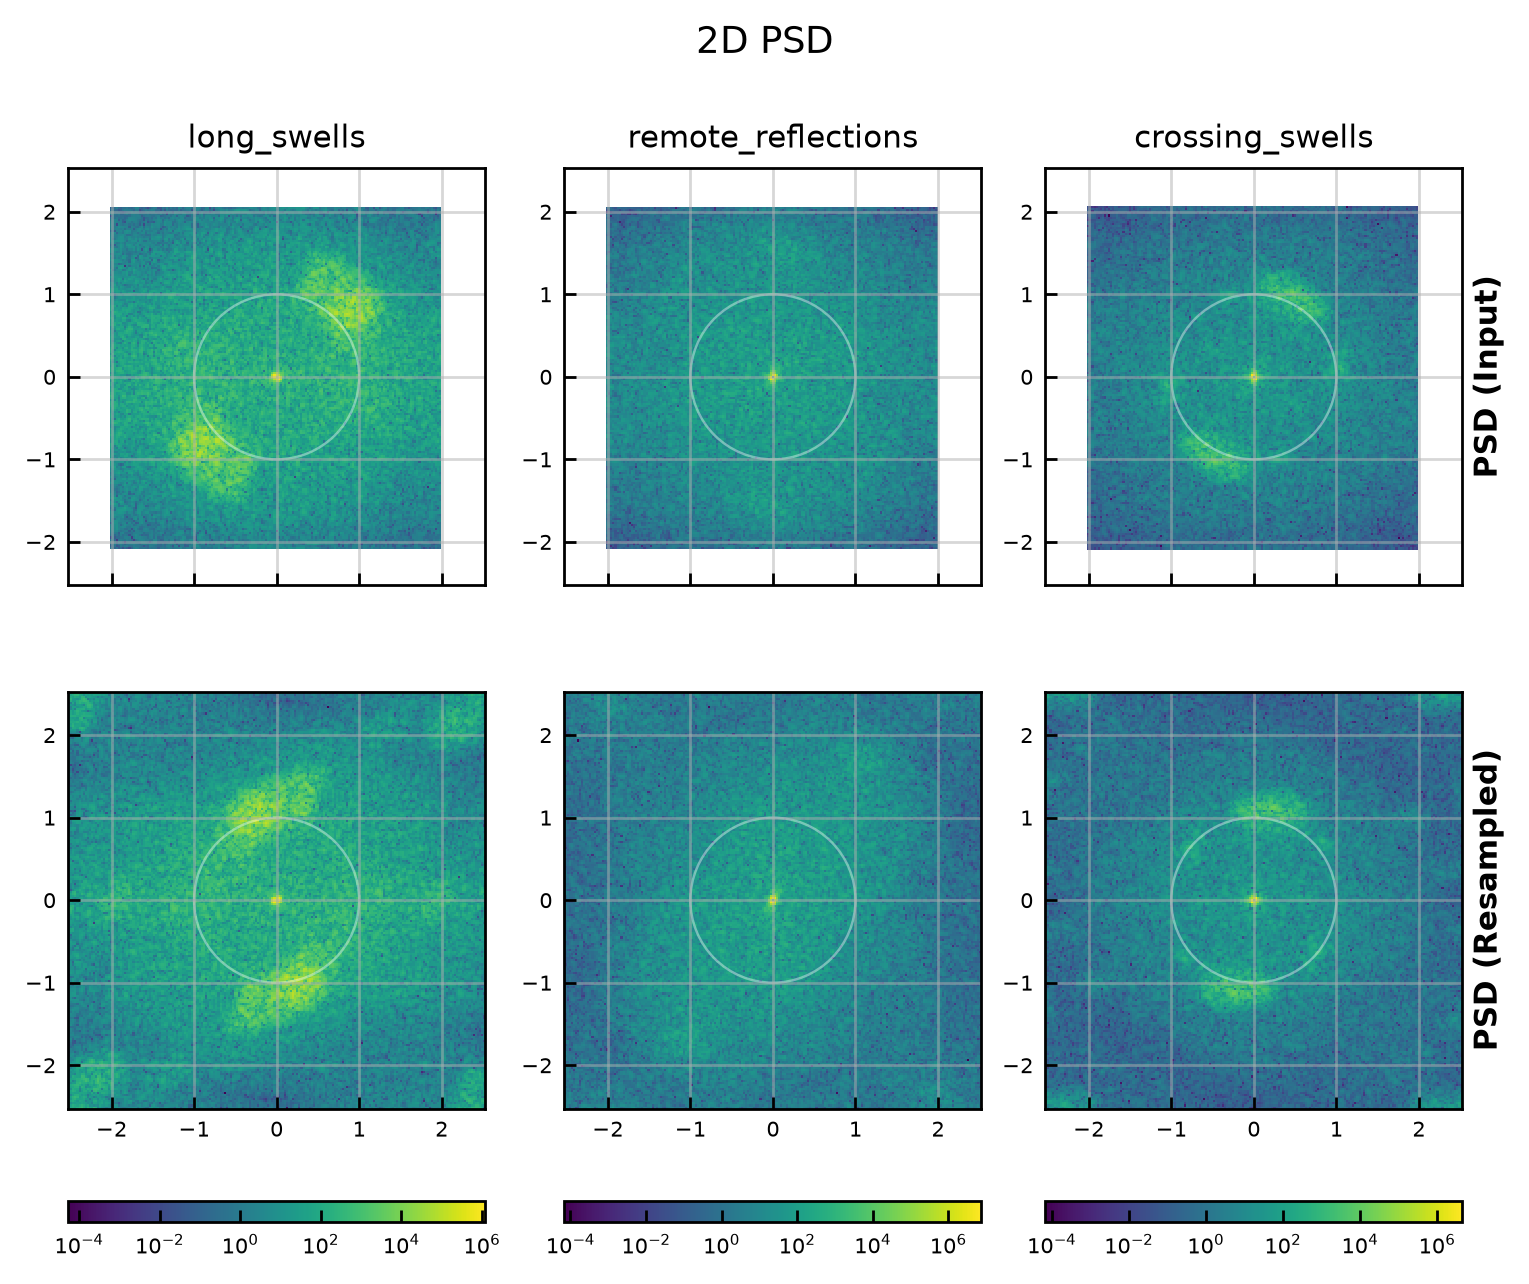

In [242]:
fig, axes = plt.subplots(
    2, 3, figsize=(6, 5), dpi=250, layout="constrained", sharex="col", sharey="col"
)
fig.suptitle("2D PSD")

for axes_col, c in zip(axes.T, cases):
    ax1, ax2 = axes_col

    vmin = min(c.psd_2d.min(), c.psd_2d_hp.min())
    vmax = max(c.psd_2d.max(), c.psd_2d_hp.max())

    im = ax1.pcolormesh(c.fx, c.fy, c.psd_2d, norm="log", vmin=vmin, vmax=vmax)
    ax2.pcolormesh(c.fx_hp, c.fy_hp, c.psd_2d_hp, norm="log", vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes_col, location="bottom")
    ax1.set_title(c.name)
    for ax in axes_col:
        ax.set_aspect("equal")

for ax, label in zip(axes[:, -1], ["PSD (Input)", "PSD (Resampled)"]):
    ax.annotate(
        label,
        xy=(1, 0.5),
        xycoords="axes fraction",
        xytext=(3, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        rotation=90,
        weight="bold",
    )

for ax in axes.flat:
    ax.add_artist(
        plt.Circle(
            (0, 0),
            radius=1.0,
            lw=0.7,
            ec="w",
            alpha=0.4,
            fc="none",
        )
    )

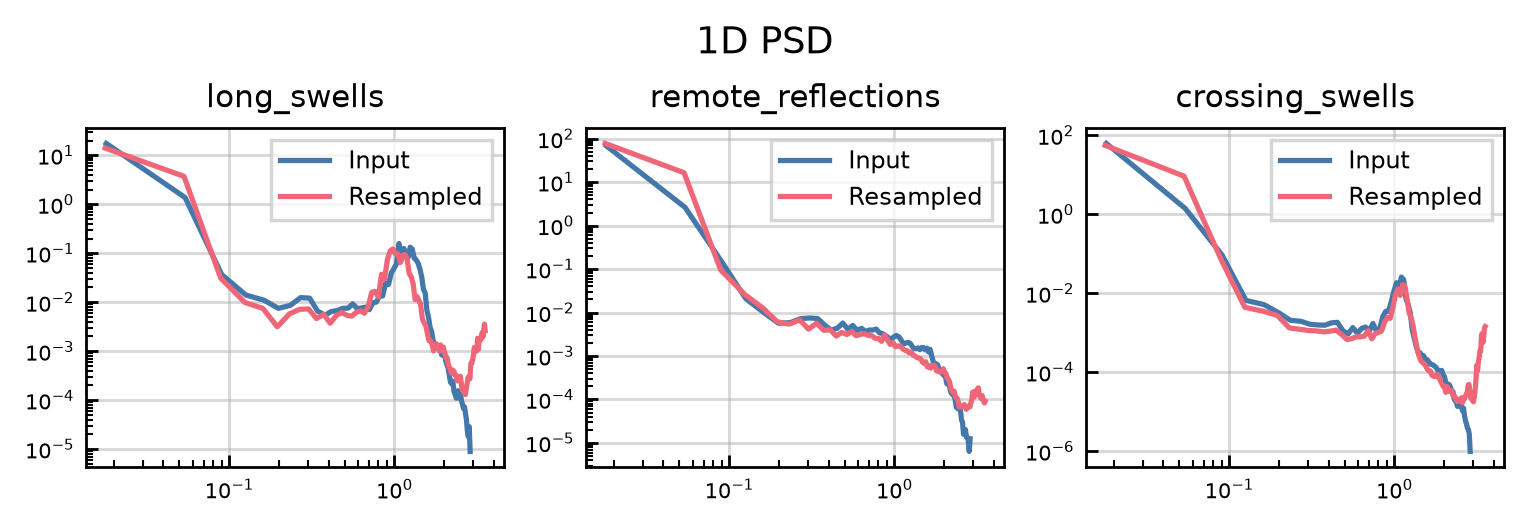

In [243]:
fig, axes = plt.subplots(
    1, 3, figsize=(6, 2), dpi=250, layout="constrained", sharex="col", sharey="col"
)
fig.suptitle("1D PSD")

cset = tc.bright

for ax, c in zip(axes, cases):
    ax.set_title(c.name)
    ax.plot(c.fr, c.psd_1d, color=cset.blue, label="Input")
    ax.plot(c.fr_hp, c.psd_1d_hp, color=cset.red, label="Resampled")
    ax.legend()
    ax.set_xscale("log")
    ax.set_yscale("log")

# Varying parameters

## Sigma

In [12]:
swath = cases[0].load()

lam = 0.5
psd_list = []
for sigma in [130, 175, 198, 250, 300, 400]:
    psd = all_in_one(swath, lam=lam, sigma_m=sigma)
    psd["psd_hp"] = psd.psd_hp.expand_dims(sigma=[sigma])
    psd_list.append(psd)
psd = xr.concat(psd_list, "sigma", data_vars=None)

13 iterations, final residual: [1.837365e-08]
13 iterations, final residual: [3.865301e-08]
13 iterations, final residual: [5.1092975e-08]
13 iterations, final residual: [8.910112e-08]
14 iterations, final residual: [3.5541806e-08]
14 iterations, final residual: [5.374982e-08]


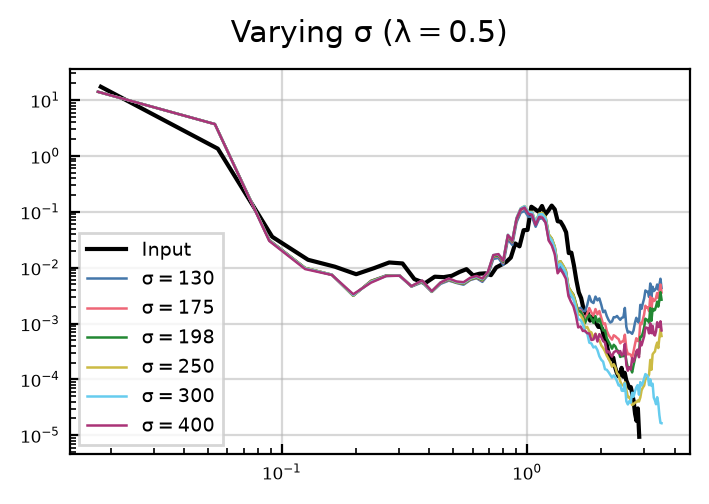

In [13]:
fig, ax = plt.subplots(figsize=(4, 2.5), dpi=200)
fig.suptitle(rf"Varying σ ($\lambda = {lam})$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.plot(psd.fr, psd.psd, color="k", label="Input")
for sigma in psd.sigma.values:
    ax.plot(
        psd.fr_hp, psd.psd_hp.sel(sigma=sigma), lw=0.9, label=rf"$\sigma = {sigma}$"
    )
ax.legend()

## Lambda

In [11]:
swath = cases[0].load()
sigma_m = 300
psd_list = []
for lam in [0, 0.01, 0.1, 0.5, 1, 10]:
    psd = all_in_one(swath, lam=lam, sigma_m=sigma_m)
    psd["psd_hp"] = psd.psd_hp.expand_dims(lam=[lam])
    psd_list.append(psd)
psd = xr.concat(psd_list, "lam", data_vars=None)

100 iterations, final residual: [0.01827668]
81 iterations, final residual: [8.912568e-08]
28 iterations, final residual: [7.422578e-08]
14 iterations, final residual: [3.5541806e-08]
10 iterations, final residual: [7.95861e-08]
5 iterations, final residual: [2.5481171e-08]


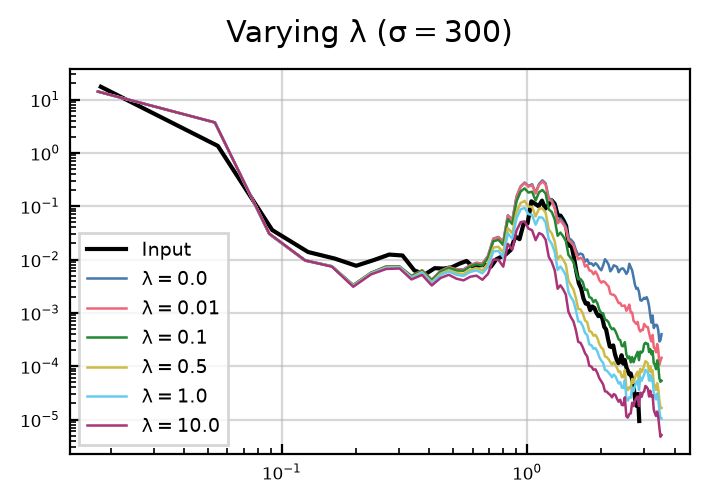

In [12]:
fig, ax = plt.subplots(figsize=(4, 2.5), dpi=200)
fig.suptitle(rf"Varying λ ($\sigma = {sigma_m})$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.plot(psd.fr, psd.psd, color="k", label="Input")
for lam in psd.lam.values:
    ax.plot(psd.fr_hp, psd.psd_hp.sel(lam=lam), lw=0.9, label=rf"$\lambda = {lam}$")
ax.legend()

## Multiple cases

In [227]:
cases = get_cases()
for case in cases:
    case.swath = case.load()

In [228]:
for case in cases:
    print(case.name)
    lam = 0.5
    psd_list = []
    for sigma in [130, 175, 198, 250, 300, 400]:
        psd = all_in_one(case.swath, lam=lam, sigma_m=sigma)
        psd["psd_hp"] = psd.psd_hp.expand_dims(sigma=[sigma])
        psd_list.append(psd)
    case.psd = xr.concat(psd_list, "sigma", data_vars=None)

long_swells
13 iterations, final residual: [1.837365e-08]
13 iterations, final residual: [3.865301e-08]
13 iterations, final residual: [5.1092975e-08]
13 iterations, final residual: [8.910112e-08]
14 iterations, final residual: [3.5541806e-08]
14 iterations, final residual: [5.374982e-08]
remote_reflections
13 iterations, final residual: [4.3262864e-09]
14 iterations, final residual: [3.4004688e-09]
14 iterations, final residual: [5.157264e-09]
14 iterations, final residual: [9.918768e-09]
14 iterations, final residual: [1.5651484e-08]
14 iterations, final residual: [2.2678963e-08]
crossing_swells
14 iterations, final residual: [1.4904897e-09]
13 iterations, final residual: [1.0147465e-08]
13 iterations, final residual: [1.4413022e-08]
14 iterations, final residual: [7.4201507e-09]
14 iterations, final residual: [1.1309635e-08]
14 iterations, final residual: [1.729292e-08]


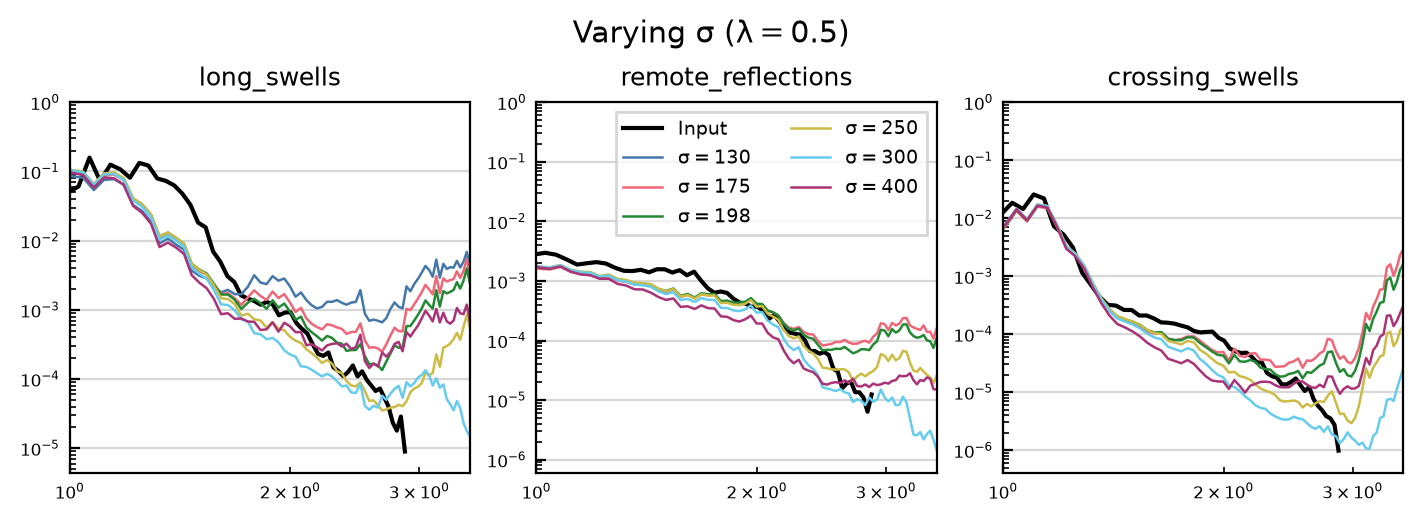

In [229]:
fig, axes = plt.subplots(
    1, 3, sharex=True, layout="constrained", figsize=(7, 2.5), dpi=200
)
fig.suptitle(rf"Varying σ ($\lambda = {lam})$")

for ax, case in zip(axes, cases):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(case.psd.fr, case.psd.psd, color="k", label="Input")
    for sigma in case.psd.sigma.values:
        ax.plot(
            case.psd.fr_hp,
            case.psd.psd_hp.sel(sigma=sigma),
            lw=0.9,
            label=rf"$\sigma = {sigma}$",
        )
    ax.set_title(rf"{case.name}")
    ax.set_xlim(1, case.psd.fr_hp[-1])
    ax.set_ylim(None, 1)
axes[1].legend(ncols=2)

In [230]:
for case in cases:
    print(case.name)
    sigma_m = 300
    psd_list = []
    for lam in [0, 0.01, 0.1, 0.5, 1, 10]:
        psd = all_in_one(case.swath, lam=lam, sigma_m=sigma_m)
        psd["psd_hp"] = psd.psd_hp.expand_dims(lam=[lam])
        psd_list.append(psd)
    case.psd = xr.concat(psd_list, "lam", data_vars=None)

long_swells
100 iterations, final residual: [0.01827668]
81 iterations, final residual: [8.912568e-08]
28 iterations, final residual: [7.422578e-08]
14 iterations, final residual: [3.5541806e-08]
10 iterations, final residual: [7.95861e-08]
5 iterations, final residual: [2.5481171e-08]
remote_reflections
100 iterations, final residual: [0.0042472]
83 iterations, final residual: [2.2833538e-08]
29 iterations, final residual: [1.6519168e-08]
14 iterations, final residual: [1.5651484e-08]
11 iterations, final residual: [6.0694867e-09]
5 iterations, final residual: [1.1821703e-08]
crossing_swells
100 iterations, final residual: [0.00744157]
80 iterations, final residual: [3.1883705e-08]
28 iterations, final residual: [2.134833e-08]
14 iterations, final residual: [1.1309635e-08]
10 iterations, final residual: [2.6391426e-08]
5 iterations, final residual: [8.699715e-09]


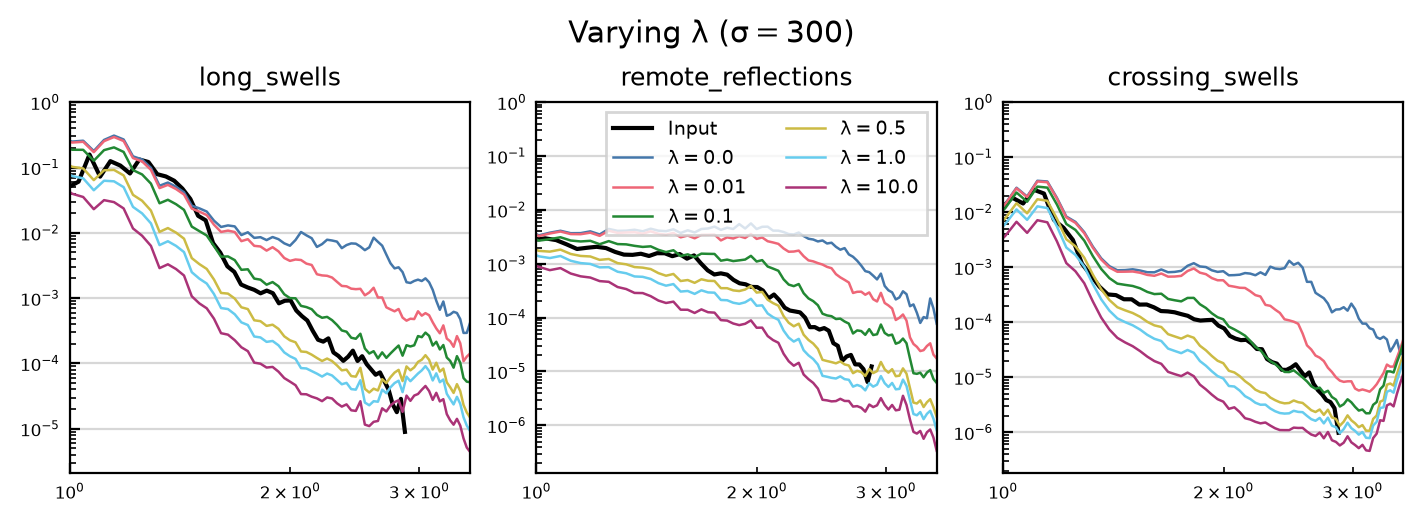

In [232]:
fig, axes = plt.subplots(
    1, 3, sharex=True, layout="constrained", figsize=(7, 2.5), dpi=200
)
fig.suptitle(rf"Varying λ ($\sigma = {sigma_m})$")

for ax, case in zip(axes, cases):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(case.psd.fr, case.psd.psd, color="k", label="Input")
    for lam in case.psd.lam.values:
        ax.plot(
            case.psd.fr_hp,
            case.psd.psd_hp.sel(lam=lam),
            lw=0.9,
            label=rf"$\lambda = {lam}$",
        )
        ax.set_title(rf"{case.name}")
    ax.set_xlim(1, case.psd.fr_hp[-1])
    ax.set_ylim(None, 1)
axes[1].legend(ncols=2)